# ResNet-18: Fine-tuning and Robustness Evaluation

Fine-tune an ImageNet-pretrained ResNet-18 on the clean EuroSAT training images (validation set used for model selection), then evaluate it on the clean test set and the four transformed test sets.

Import Necessary Libraries

In [2]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from scipy.stats import binomtest

Settings


In [3]:
SEED = 42
IMG_SIZE = 224        # input size expected by the ImageNet-pretrained models
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 1e-4
NUM_CLASSES = 10

DATA_DIR = Path("EuroSAT")
RESULTS_DIR = Path("results/resnet18")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = RESULTS_DIR / "resnet18_best.pth"   # *.pth files are ignored by git

# Test sets: name -> folder that holds the class subfolders
TEST_SETS = {
    "clean": DATA_DIR,
    "gaussian_noise": DATA_DIR / "transformed_test/gaussian_noise",
    "gaussian_blur": DATA_DIR / "transformed_test/gaussian_blur",
    "rotated": DATA_DIR / "transformed_test/rotated",
    "brightness_contrast": DATA_DIR / "transformed_test/brightness_contrast",
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    device = torch.device("mps")      # Apple Silicon GPU
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Using device:", device)

Using device: mps


Data Loading

In [4]:
class EuroSATDataset(Dataset):
    """Reads image paths and labels from a split CSV (Filename, Label)."""
    def __init__(self, csv_path, image_root, transform):
        self.df = pd.read_csv(csv_path)
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(self.image_root / row["Filename"]).convert("RGB")
        return self.transform(image), int(row["Label"]), row["Filename"]

# Same preprocessing for every split: resize + ImageNet normalization (no training augmentation)
preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BICUBIC),  # same as ViT
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = EuroSATDataset(DATA_DIR / "train.csv", DATA_DIR, preprocess)
val_ds = EuroSATDataset(DATA_DIR / "validation.csv", DATA_DIR, preprocess)

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Train images:", len(train_ds))
print("Validation images:", len(val_ds))

Train images: 18900
Validation images: 5400


Model: ImageNet-pretrained ResNet-18 with a new 10-class output layer

In [5]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/vkbea/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


Training (best epoch chosen by validation accuracy)

In [6]:
def run_epoch(model, loader, train):
    model.train() if train else model.eval()
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels, _ in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            count += labels.size(0)
    return total_loss / count, correct / count

history = []
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, train=True)
    val_loss, val_acc = run_epoch(model, val_loader, train=False)
    history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                    "val_loss": val_loss, "val_acc": val_acc})
    print(f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f}, acc {train_acc:.4f} "
          f"| val loss {val_loss:.4f}, acc {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), MODEL_PATH)
        print("  Saved new best model")

pd.DataFrame(history).to_csv(RESULTS_DIR / "training_history.csv", index=False)
print("Best validation accuracy:", round(best_val_acc, 4))

Epoch 1/5 | train loss 0.2054, acc 0.9353 | val loss 0.1218, acc 0.9578
  Saved new best model
Epoch 2/5 | train loss 0.0597, acc 0.9810 | val loss 0.0653, acc 0.9780
  Saved new best model
Epoch 3/5 | train loss 0.0334, acc 0.9898 | val loss 0.0789, acc 0.9724
Epoch 4/5 | train loss 0.0251, acc 0.9917 | val loss 0.0674, acc 0.9787
  Saved new best model
Epoch 5/5 | train loss 0.0207, acc 0.9936 | val loss 0.0699, acc 0.9785
Best validation accuracy: 0.9787


Evaluation on the clean and transformed test sets

In [7]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

def predict(image_root):
    ds = EuroSATDataset(DATA_DIR / "test.csv", image_root, preprocess)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    rows = []
    with torch.no_grad():
        for images, labels, filenames in loader:
            preds = model(images.to(device)).argmax(1).cpu().numpy()
            for f, y, p in zip(filenames, labels.numpy(), preds):
                rows.append({"Filename": f, "Label": int(y), "Pred": int(p), "Correct": int(y == p)})
    return pd.DataFrame(rows)

predictions = {}
for name, root in TEST_SETS.items():
    predictions[name] = predict(root)
    predictions[name].to_csv(RESULTS_DIR / f"predictions_{name}.csv", index=False)
    print(f"{name:20s} accuracy: {predictions[name]['Correct'].mean():.4f}")

clean                accuracy: 0.9826
gaussian_noise       accuracy: 0.3167
gaussian_blur        accuracy: 0.5052
rotated              accuracy: 0.8744
brightness_contrast  accuracy: 0.9067


Summary and statistical test

For each transformed test set we compare it with the clean test set on the same 2,700 images:
- **Accuracy drop** = clean accuracy minus transformed accuracy
- **Flips**: correct-to-wrong (correct on clean, wrong after the transformation) and wrong-to-correct
- **McNemar's exact test** (H0: the transformation does not change accuracy) on those flip counts

In [8]:
clean = predictions["clean"].set_index("Filename")["Correct"]
summary = []

for name, df_pred in predictions.items():
    acc = df_pred["Correct"].mean()
    row = {"model": "ResNet-18", "test_set": name, "accuracy": acc}
    if name != "clean":
        transformed = df_pred.set_index("Filename")["Correct"].reindex(clean.index)
        correct_to_wrong = int(((clean == 1) & (transformed == 0)).sum())
        wrong_to_correct = int(((clean == 0) & (transformed == 1)).sum())
        n_flips = correct_to_wrong + wrong_to_correct
        p_value = binomtest(min(correct_to_wrong, wrong_to_correct), n_flips, 0.5).pvalue if n_flips > 0 else 1.0
        row.update({
            "accuracy_drop": clean.mean() - acc,
            "correct_to_wrong": correct_to_wrong,
            "wrong_to_correct": wrong_to_correct,
            "flip_rate": correct_to_wrong / int((clean == 1).sum()),
            "mcnemar_p_value": p_value,
        })
    summary.append(row)

summary_df = pd.DataFrame(summary)
summary_df.to_csv(RESULTS_DIR / "summary.csv", index=False)
summary_df

,model,test_set,accuracy,accuracy_drop,correct_to_wrong,wrong_to_correct,flip_rate,mcnemar_p_value
0,ResNet-18,clean,0.982593,NaN,NaN,NaN,NaN,NaN
1,ResNet-18,gaussian_noise,0.316667,0.665926,1804.0,6.0,0.679985,0.000000e+00
2,ResNet-18,gaussian_blur,0.505185,0.477407,1299.0,10.0,0.489634,0.000000e+00
3,ResNet-18,rotated,0.874444,0.108148,313.0,21.0,0.117980,6.287376e-68
4,ResNet-18,brightness_contrast,0.906667,0.075926,216.0,11.0,0.081417,1.577391e-50


Accuracy by test set

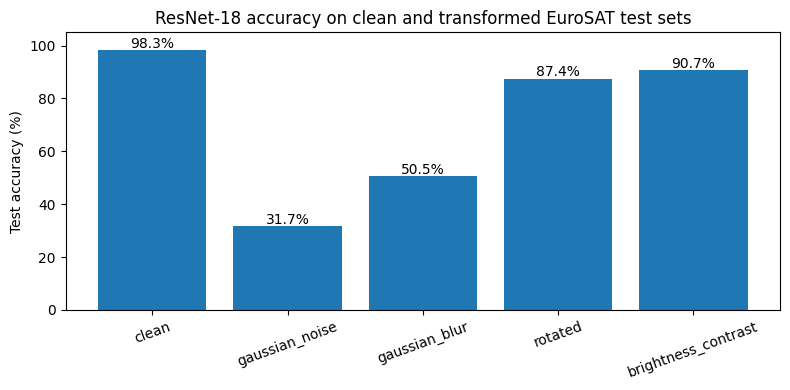

In [9]:
plt.figure(figsize=(8, 4))
plt.bar(summary_df["test_set"], summary_df["accuracy"] * 100)
for i, acc in enumerate(summary_df["accuracy"] * 100):
    plt.text(i, acc + 1, f"{acc:.1f}%", ha="center")
plt.ylabel("Test accuracy (%)")
plt.title("ResNet-18 accuracy on clean and transformed EuroSAT test sets")
plt.ylim(0, 105)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_by_test_set.png", dpi=200)
plt.show()